# 14a — From cell density to a displayed tumour boundary

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/brains-to-models/blob/main/code/notebooks/14a_growth_density_and_thresholds.ipynb)

**Related resources:** [Paper](https://github.com/arvidl/brains-to-models/blob/main/paper/main.pdf) · [Presentation guide](https://github.com/arvidl/brains-to-models/blob/main/talk/resources.md)

## Why this notebook

A growth equation produces a density field, while an image display often shows a coloured region with an apparently definite edge. The conversion between them is a modelling choice. Here we change dispersal and display thresholds separately, so we can ask which change belongs to the dynamics and which belongs to the observation.

The domain is an **invented two-dimensional tissue map**, not BrainWeb or a patient slice. Its labels provide a controlled first step toward the three-dimensional BrainWeb example in notebook 14b. Notebook 13 develops the numerical verification ideas used here.

### Learning goals

1. Explain normalized density, integrated density and threshold area as different quantities.
2. Compare homogeneous and tissue-dependent dispersal while keeping the initial state and growth rate fixed.
3. Predict how changing only a display threshold changes the apparent boundary.
4. Use a known solution and a conservation check to assess the shared solver.

## Concepts and two reading paths

<details open>
<summary><strong>For biomedical and imaging readers</strong></summary>

**Cell density** is the number of cells per volume. We use $u=c/K$, the fraction of an assumed carrying capacity $K$, so $u=0.2$ means one fifth of that capacity. It is not a 20% probability of cancer. A constant $K$ is assumed throughout this normalization.

**Dispersal** moves density between neighbouring locations; **proliferation** increases it locally, with slowing as capacity is approached. Tissue labels determine the assumed dispersal coefficient. They do not measure that coefficient.

A **threshold area** counts pixels at or above a chosen density fraction. An MRI signal would require its own measurement model; no universal density threshold is assigned to enhancement or FLAIR. The **integral of density** instead weights every pixel by its density. The two quantities answer different questions.

</details>

<details>
<summary><strong>For computational readers</strong></summary>

The state is $u\in[0,1]$ on a cell-centred grid. A scalar field $D(x,y)$ can vary spatially while remaining locally isotropic: it does not encode a preferred fibre direction. Conservative face exchanges discretize $\nabla\cdot(D\nabla u)$, with harmonic means at interfaces and zero flux at domain boundaries. Exact local logistic flow follows each explicit diffusion step. This composition is first order in time.

The homogeneous comparison uses the arithmetic mean of the tissue-dependent $D$ over the same domain. This matches one declared summary of the coefficients, not an effective diffusion constant or an equal growth trajectory. The geometry, initial state, growth rate and numerical settings are shared.

</details>

### Run in Colab or locally

Click **Open in Colab**, connect to a standard **CPU** runtime and run all cells in order. Setup obtains the shared code and dependencies. Locally, use the [environment instructions](https://github.com/arvidl/brains-to-models/blob/main/README.md#run-the-notebooks), select the project kernel and restart and run all cells. No earlier notebook needs to have run.

Save a notebook copy in Drive to retain edits. Download generated figures or JSON records before a Colab runtime ends. Results are written under the ignored `.build/` directory, separately from the saved notebook.

In [1]:
# Locate the shared code locally, or download a small checkout in Colab.
import os
from pathlib import Path
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("BRAINSMODELS_REPO_URL",
                          "https://github.com/arvidl/brains-to-models.git")
if IN_COLAB:
    root = Path(os.environ.get("BRAINSMODELS_COLAB_ROOT",
                               "/content/brains-to-models"))
    if not (root / "code/src/brainsmodels").is_dir():
        # Sparse checkout keeps the large presentation out of the runtime.
        subprocess.check_call(["git", "clone", "--depth", "1", "--filter=blob:none",
                               "--sparse", "--branch", "main", REPO_URL, str(root)])
        subprocess.check_call(["git", "-C", str(root), "sparse-checkout", "set",
                               "code", "paper/figures"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "numpy>=1.26", "matplotlib>=3.8", "ipywidgets>=8.1"])
else:
    here = Path.cwd().resolve()
    root = next((p for p in (here, *here.parents)
                 if (p / "pyproject.toml").is_file()
                 and (p / "code/src/brainsmodels").is_dir()), None)
    if root is None:
        raise RuntimeError("Open this notebook inside a brains-to-models checkout, "
                           "or use its Open in Colab badge.")

src = str(root / "code/src")
if src not in sys.path:
    sys.path.insert(0, src)
# Keep relative exercise paths consistent in Colab, JupyterLab and Cursor.
os.chdir(root / "code/notebooks")
repo = ROOT = root
import json
import numpy as np
import matplotlib.pyplot as plt
print("Checkout:", root)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__)
# End of shared setup.
if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()

from brainsmodels.growth_extension import simulate, gaussian_seed, tissue_diffusion
from brainsmodels.growth_verification import logistic
from brainsmodels import growth_lessons as lessons
OUTPUT = root / '.build/growth-14a'
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

def show_figure(fig, name):
    fig.savefig(OUTPUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


Python: 3.12.2 | NumPy: 2.5.2


## 1. State the model before looking at the result

With a spatially constant carrying capacity, the normalized Fisher–KPP equation is

$$\frac{\partial u}{\partial t}=\nabla\cdot(D\nabla u)+\rho u(1-u).$$

Read it as **change in density = redistribution + local growth**. The gradient $\nabla u$ describes spatial differences; the divergence $\nabla\cdot$ converts the resulting transfers into a local net gain or loss. $D$ is in mm²/day and $\rho$ in day⁻¹. This population equation has no explicit switching between migratory and proliferative cell states.

The grid has 1 mm spacing. White-labelled tissue uses $D=0.5$ mm²/day; grey-labelled tissue uses $D=0.1$ mm²/day; both use $\rho=0.04$ day⁻¹. CSF-labelled and outside cells are excluded, with no transfer through their faces. The shared initial seed is a Gaussian with standard deviation 6 mm and peak $u=0.12$, centred at (−14, 0) mm and masked to the included tissue. These are assigned teaching values and boundary assumptions.

**Predict:** will equal mean diffusivity guarantee equal final density maps? Will removing transport prevent local growth?

Homogeneous D: 0.3188 mm²/day
Grid: (81, 81) | spacing: 1 mm | rho: 0.04/day
Growth only | day-90 integral: 385.18 mm² | largest step: 0.4 days
Homogeneous D | day-90 integral: 527.38 mm² | largest step: 0.4 days
Tissue-dependent D | day-90 integral: 547.67 mm² | largest step: 0.4 days


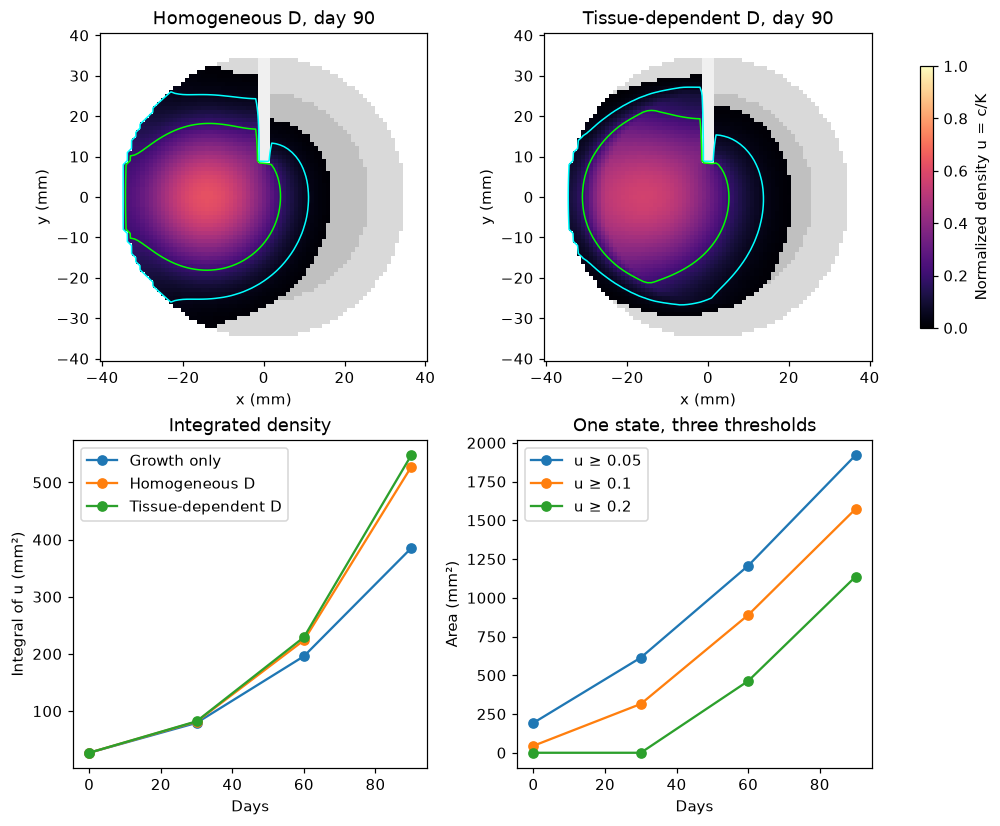

In [2]:
axes, labels, runs, mean_D = lessons.planar_experiment()
print('Homogeneous D:', round(mean_D, 4), 'mm²/day')
print('Grid:', labels.shape, '| spacing: 1 mm | rho: 0.04/day')
for label, run in runs.items():
    print(label, '| day-90 integral:', round(run.integral[-1], 2), 'mm²',
          '| largest step:', run.largest_step, 'days')
show_figure(lessons.plot_planar(axes, labels, runs), 'density-and-thresholds')

### Read the figure

The upper panels share the same colour scale and initial state. Cyan and green contours mark $u=0.05$ and $u=0.2$; they are readings of the density, not different simulations. The grey background is the constructed tissue map. Faster assigned white-tissue dispersal and the closed CSF slit alter the shape of spread.

The lower-left panel integrates density. With logistic growth, spatial redistribution can also change total growth: moving density away from crowded regions changes the local factor $1-u$. Therefore, matching mean $D$ need not match integrated density. The lower-right panel keeps the dynamics fixed and changes only the reading threshold.

## 2. Work through the measurement operation

For pixel area $a=\Delta x\Delta y$, integrated density is

$$B_{2D}(t)=a\sum_i u_i(t),\qquad A_\tau(t)=a\sum_i\mathbf{1}[u_i(t)\geq\tau].$$

The symbol $\mathbf{1}[\cdot]$ is one when its condition holds, and zero otherwise. $B_{2D}$ has units mm² because $u$ is dimensionless. It is not a cell count or a three-dimensional tumour volume. $A_\tau$ counts every selected pixel equally.

For example, one 1 mm² pixel with $u=0.8$ contributes 0.8 mm² to $B_{2D}$. It contributes 1 mm² to $A_{0.2}$ and 0 to $A_{0.9}$. No biological state changes when the threshold changes.

In [3]:
run = runs['Tissue-dependent D']
print('Same day-90 density field:')
for threshold in [.05, .1, .2]:
    print(f'  u >= {threshold:.2f}: {run.threshold_measure(threshold)[-1]:.0f} mm²')
assert np.all(run.threshold_measure(.05) >= run.threshold_measure(.2))
print('Density integral:', round(run.integral[-1], 2), 'mm²')

Same day-90 density field:
  u >= 0.05: 1920 mm²
  u >= 0.10: 1573 mm²
  u >= 0.20: 1136 mm²
Density integral: 547.67 mm²


## 3. Verify two different properties

Turn off dispersal: the exact logistic solution should hold independently at every pixel. Turn off growth instead: no-flux diffusion should conserve the integrated density. Neither check alone tests all spatial boundaries; notebook 13 shows a deliberately wrong boundary that preserves the total.

The solver also checks its diffusion positivity bound before running. Under the permitted step, every transport update is a weighted average of neighbouring densities. There is no clipping to conceal an unstable result.

In [4]:
inside = np.isin(labels, [2, 3])
initial = gaussian_seed(axes, (-14., 0.), domain=inside)
reaction = simulate(initial, 0., .04, [0., 90.], spacing_mm=(1., 1.), dt=.4, domain=inside)
np.testing.assert_allclose(reaction.density[-1], logistic(initial, .04, 1., 90.), atol=2e-14)
transport = simulate(initial, tissue_diffusion(labels), 0., [0., 90.],
                     spacing_mm=(1., 1.), dt=.4, domain=inside)
np.testing.assert_allclose(transport.integral, transport.integral[0], rtol=1e-12)
print('Logistic limit and no-growth conservation passed.')
print('Largest balance residual in the growth runs:', max(r.balance_error for r in runs.values()))

Logistic limit and no-growth conservation passed.
Largest balance residual in the growth runs: 2.2737367544323206e-13


## Interactive experiment: change dynamics, then change the reading

Set the white- and grey-matter diffusivities, proliferation rate and requested time step, then press **Run comparison**. The three comparison runs share the same initial state and domain. An unstable time step is rejected with its permitted bound; it is not silently shortened or hidden by clipping.

After a run, **Read day** and **Density threshold** read cached states immediately. They do not rerun the solver. Snapshots are stored every 10 days from 0 to 120. If you change a simulation parameter, the status identifies the previous result until you press Run again. These explorations leave the fixed example and paper figures unchanged.

**Try:** predict what happens when the two diffusivities become equal; then run that case. Next change only the threshold. Which quantities changed in each experiment?

Widgets require a running Colab, JupyterLab or Cursor notebook kernel. GitHub shows the saved reference figures above; run this cell to create the controls.

In [5]:
from IPython.display import display
from brainsmodels.growth_widgets import planar_explorer

explorer = planar_explorer()
display(explorer.widget)

## 4. What the result establishes

These calculations show how a specified equation, tissue map and reading rule produce different outputs. They do not estimate dispersal from an MRI, identify a clinical margin or predict an individual patient's progression. A constant carrying capacity, fixed tissue geometry and closed CSF interfaces are assumptions worth questioning for a particular use.

**Takeaway:** a displayed boundary depends on both the evolving state and the rule used to read it.

**Check question:** if a threshold area doubles, what additional information would you need before concluding that the number of tumour cells doubled?

## Exercises and worked reasoning

1. **Biomedical/imaging:** keep the final field fixed and raise the threshold. Which quantities change?
2. **Computational:** set both tissue diffusivities to the same value. What comparison should become identical?
3. **Both paths:** how would you turn this 2-D area into a slice-volume estimate, and which new assumption would that introduce?

<details><summary><strong>Show reasoning</strong></summary>

1. The selected area and boundary change; the underlying density and its integral do not.
2. With the same domain, initial state, rate and time steps, the homogeneous and tissue-dependent runs should agree. Tissue names alone do not change an equation.
3. Multiply area by an explicitly assumed slice thickness and divide mm³ by 1,000 for mL. This assumes the 2-D state represents that entire slab; it does not reconstruct a whole tumour.

</details>

## Further reading and implementation

- [Swanson, Alvord and Murray (2000)](https://doi.org/10.1046/j.1365-2184.2000.00177.x): a primary glioma modelling study distinguishing grey- and white-matter motility.
- [Hatzikirou et al. (2012)](https://doi.org/10.1093/imammb/dqq011): migration/proliferation switching as a separate mechanistic hypothesis.
- [Tissue/threshold teaching examples in the companion repository](https://github.com/arvidl/AI-assisted-glioma-research/blob/b9c1b512d93426392db6c0571f47f1b54ff05eec/notebooks/02_tumor_dynamics.ipynb).
- [Shared numerical implementation](https://github.com/arvidl/brains-to-models/blob/main/code/src/brainsmodels/growth_extension.py), adapted educationally from the companion's MIT-licensed examples. The local solver is independent of its implementation.

Continue with [14b: BrainWeb anatomy](https://github.com/arvidl/brains-to-models/blob/main/code/notebooks/14b_brainweb_growth.ipynb).